# 3.1 Exploratory Data Analysis

**Data:** IPUMS USA extract `usa_00008` (ACS 2008, 2016, 2024), decoded by
`parser.py` and reduced by `clean_ipums_features.py` → `usa_00008_cleaned.csv`.

**Target:** `DIVINYR` – *divorced in the past year* (`Yes` vs `Blank (No)`).
It is only defined for its universe (people aged 15+ who have ever married), so
rows with `N/A` / `Suppressed` are not in scope for modelling.

The EDA is organised around the questions that drive preprocessing in 3.2:

| Section | What we examine | Feeds into 3.2 |
|---|---|---|
| 1. Dataset overview | rows, columns, dtypes, duplicates | cleaning requirements |
| 2. Missing values | % missing per feature (incl. IPUMS N/A codes) | imputation vs removal |
| 3. Numeric distributions | histograms, box plots, skew, outliers | transforms, clipping, scaling |
| 4. Categorical distributions | frequencies, cardinality, rare levels | encoding strategy |
| 5. Correlations | Spearman heatmap, Cramér's V | redundant features |
| 6. Target relationships | divorce rate by feature | predictive signal, leakage |
| 7. Class balance | target distribution (weighted / unweighted) | imbalance handling |

Every problem found is appended to `issues`, summarised at the end (section 8).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.api.types import union_categoricals
from scipy.stats import chi2_contingency
from sklearn.feature_selection import mutual_info_classif

# ---------------------------------------------------------
# Configuration
# ---------------------------------------------------------
DATA_FILE = "usa_00008_sample1000.csv"
FIG_DIR = Path("figures/eda")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# The full extract has millions of rows. Use a fraction < 1 for fast iteration;
# set to 1.0 for the final run that produces the report figures.
SAMPLE_FRAC = 1.0
RANDOM_STATE = 42
CHUNK_SIZE = 1_000_000

TARGET_RAW = "DIVINYR_LABEL"
TARGET = "divorced"          # 1 = divorced in past year, 0 = not
TARGET_POS = "Yes"
TARGET_NEG = "Blank (No)"
WEIGHT = "PERWT"

# Numeric variables kept by clean_ipums_features.py
NUMERIC_COLS = [
    "AGE", "FAMSIZE", "NCHILD", "UHRSWORK", "YRMARR",
    "RENT", "VALUEH", "HHINCOME", "INCTOT", "FTOTINC",
    "INCWAGE", "INCEARN", "POVERTY",
]

# Categorical features (label versions) kept by clean_ipums_features.py.
# Selecting explicitly means the notebook also works on the decoded (uncleaned)
# file or a sample of it – any other columns are ignored.
CATEGORICAL_COLS = [
    "HHTYPE_LABEL", "REGION_LABEL", "STATEFIP_LABEL", "METRO_LABEL",
    "OWNERSHP_LABEL", "COUPLETYPE_LABEL", "SEX_LABEL", "MARST_LABEL",
    "MARRNO_LABEL", "DIVINYR_LABEL", "RACE_LABEL", "HISPAN_LABEL",
    "EDUC_LABEL", "EMPSTAT_LABEL", "LABFORCE_LABEL", "CLASSWKR_LABEL",
    "WKSWORK2_LABEL", "MIGRATE1_LABEL", "VEHICLES_LABEL",
]

# IPUMS codes that mean "N/A / not in universe / missing" for numeric
# variables (from usa_00008.xml + IPUMS codebook). These are not real values.
NUMERIC_NA_CODES = {
    "AGE": [999],
    "UHRSWORK": [0],                 # N/A (not working)
    "YRMARR": [0],                   # N/A (never married)
    "RENT": [0],                     # N/A (owners, GQ)
    "VALUEH": [9999998, 9999999],    # Missing / N/A (renters)
    "HHINCOME": [9999999],
    "INCTOT": [9999998, 9999999],
    "FTOTINC": [9999998, 9999999],
    "INCWAGE": [999998, 999999],
    "POVERTY": [0],                  # N/A (group quarters)
}

# Category labels that mean "missing / not applicable"
CATEGORICAL_NA_LABELS = {
    "", "N/A", "Missing", "Missing/blank", "Blank, missing", "Not Applicable",
    "Unknown", "Unknown/Illegible", "Illegible",
    "Unclassifiable (employment status unknown)",
    "HHTYPE could not be determined", "State not identified", "Not identified",
}

# Report-friendly plot style: one hue for single series, two for target classes
BLUE, ORANGE = "#2a78d6", "#eb6834"
CLASS_PALETTE = {0: BLUE, 1: ORANGE}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})

issues = []  # (section, feature, problem, suggested action for 3.2)


def add_issue(section, feature, problem, action):
    issues.append({"section": section, "feature": feature,
                   "problem": problem, "action_3_2": action})


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def weighted_rate(y, w):
    return np.average(y, weights=w) if len(y) else np.nan

## 0. Load data

Read in chunks (the CSV is several GB). Label columns are read as
`category` to keep memory low. `keep_default_na=False` matters: otherwise
pandas silently turns the IPUMS label `"N/A"` into NaN and we lose the
distinction between *blank* and *not in universe*.

In [2]:
header = pd.read_csv(DATA_FILE, nrows=0).columns.tolist()
numeric_cols = [c for c in NUMERIC_COLS if c in header]
label_cols = [c for c in CATEGORICAL_COLS if c in header]
use_cols = ["YEAR", WEIGHT] + numeric_cols + label_cols

dtypes = {c: "float64" for c in numeric_cols + [WEIGHT]}
dtypes.update({c: "category" for c in label_cols})
dtypes["YEAR"] = "Int64"

parts = []
for chunk in pd.read_csv(DATA_FILE, usecols=use_cols, dtype=dtypes,
                         keep_default_na=False, na_values=[""],
                         chunksize=CHUNK_SIZE):
    if SAMPLE_FRAC < 1:
        chunk = chunk.sample(frac=SAMPLE_FRAC, random_state=RANDOM_STATE)
    parts.append(chunk)

# Chunks can have different category sets -> union them so dtype stays categorical
raw = pd.concat(parts, ignore_index=True)
for c in label_cols:
    raw[c] = union_categoricals([p[c] for p in parts], ignore_order=True)
del parts

print(f"Loaded {len(raw):,} rows × {raw.shape[1]} columns "
      f"(SAMPLE_FRAC={SAMPLE_FRAC})")
raw.head()

Loaded 1,000 rows × 32 columns (SAMPLE_FRAC=1.0)


,YEAR,HHTYPE_LABEL,REGION_LABEL,STATEFIP_LABEL,METRO_LABEL,OWNERSHP_LABEL,RENT,HHINCOME,VALUEH,COUPLETYPE_LABEL,...,LABFORCE_LABEL,CLASSWKR_LABEL,WKSWORK2_LABEL,UHRSWORK,INCTOT,FTOTINC,INCWAGE,INCEARN,POVERTY,MIGRATE1_LABEL
0,2008,"Female householder, no husband present",South Atlantic Division,Florida,In metropolitan area: Central/principal city s...,Owned or being bought (loan),0.0,62200.0,475000.0,NaN,...,"Yes, in the labor force",Self-employed,50-52 weeks,40.0,39200.0,62200.0,20000.0,20000.0,281.0,Same house
1,2024,"Female householder, no husband present",South Atlantic Division,Virginia,In metropolitan area: Not in central/principal...,Owned or being bought (loan),0.0,90900.0,625000.0,N/A,...,"Yes, in the labor force",Works for wages,50-52 weeks,40.0,90000.0,90900.0,90000.0,90000.0,365.0,Moved within state
2,2016,N/A,West North Central Div.,Iowa,Not in metropolitan area,N/A,0.0,9999999.0,9999999.0,NaN,...,"No, not in the labor force",N/A,N/A,0.0,43200.0,9999999.0,0.0,0.0,0.0,Moved within state
3,2016,"Female householder, living alone",South Atlantic Division,Virginia,Metropolitan status indeterminable (mixed),Owned or being bought (loan),0.0,50400.0,480000.0,NaN,...,"No, not in the labor force",N/A,N/A,0.0,50400.0,50400.0,0.0,0.0,441.0,Same house
4,2024,"Female householder, no husband present",South Atlantic Division,South Carolina,In metropolitan area: Central/principal city s...,Owned or being bought (loan),0.0,67300.0,400000.0,N/A,...,"No, not in the labor force",N/A,N/A,0.0,12000.0,67300.0,0.0,0.0,208.0,Same house


## 1. Dataset overview
Rows, columns, data types, memory and duplicates.

In [3]:
overview = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "n_unique": raw.nunique(),
    "example": raw.iloc[0],
})
print(f"Rows: {len(raw):,}   Columns: {raw.shape[1]}   "
      f"Memory: {raw.memory_usage(deep=True).sum() / 1024**2:,.0f} MB")
overview

Rows: 1,000   Columns: 32   Memory: 0 MB


,dtype,n_unique,example
YEAR,Int64,3,2008
HHTYPE_LABEL,category,9,"Female householder, no husband present"
REGION_LABEL,category,9,South Atlantic Division
STATEFIP_LABEL,category,50,Florida
METRO_LABEL,category,5,In metropolitan area: Central/principal city s...
OWNERSHP_LABEL,category,3,Owned or being bought (loan)
RENT,float64,69,0.0
HHINCOME,float64,698,62200.0
VALUEH,float64,206,475000.0
COUPLETYPE_LABEL,category,4,NaN


In [4]:
print("Rows per survey year:")
display(raw["YEAR"].value_counts().sort_index().to_frame("rows"))

# Constant columns carry no information
constant = [c for c in raw.columns if raw[c].nunique(dropna=False) <= 1]
for c in constant:
    add_issue("1 Overview", c, "Constant column", "Drop")
print("Constant columns:", constant or "none")

Rows per survey year:


,rows
YEAR,
2008,319
2016,342
2024,339


Constant columns: none


In [5]:
# Duplicates. Household/person IDs were dropped during cleaning, so identical
# rows can be different people with the same profile – report, don't auto-drop.
n_dup = raw.duplicated().sum()
print(f"Fully duplicated rows: {n_dup:,} ({n_dup / len(raw):.2%})")
if n_dup:
    add_issue("1 Overview", "(all)",
              f"{n_dup:,} duplicate rows ({n_dup / len(raw):.2%}); IDs removed so "
              "these may be distinct people",
              "Keep (survey weights apply per person); verify with SERIAL/PERNUM if needed")

Fully duplicated rows: 0 (0.00%)


### Define the modelling universe and target
`DIVINYR` is `N/A` for people outside its universe (never married, under 15)
and `Suppressed` in some cases. Those rows cannot be labelled.

In [6]:
print(raw[TARGET_RAW].value_counts(dropna=False).to_frame("rows"))

df = raw[raw[TARGET_RAW].isin([TARGET_POS, TARGET_NEG])].copy()
df[TARGET] = (df[TARGET_RAW] == TARGET_POS).astype("int8")
df[TARGET_RAW] = df[TARGET_RAW].cat.remove_unused_categories()

out_of_universe = len(raw) - len(df)
print(f"\nIn target universe: {len(df):,} rows "
      f"({out_of_universe:,} rows dropped as N/A / Suppressed)")
add_issue("1 Overview", TARGET_RAW,
          f"{out_of_universe / len(raw):.1%} of rows have no target (N/A or Suppressed)",
          "Restrict modelling data to DIVINYR in {Yes, Blank (No)}")

# Everything below is analysed on the target universe
feature_label_cols = [c for c in label_cols if c != TARGET_RAW]

               rows
DIVINYR_LABEL      
Blank (No)      989
Yes              11

In target universe: 1,000 rows (0 rows dropped as N/A / Suppressed)


## 2. Missing values
Two kinds of missing in IPUMS:
* **true blanks** (empty cells), and
* **coded N/A** – sentinel numbers (e.g. `9999999`) or labels (`"N/A"`).
  Most of these are *structural* ("not in universe": renters have no house
  value, non-workers have no hours), which affects how we impute.

In [7]:
def missing_mask(frame):
    m = frame.isna()
    for c, codes in NUMERIC_NA_CODES.items():
        if c in frame:
            m[c] |= frame[c].isin(codes)
    for c in feature_label_cols:
        m[c] |= frame[c].astype(str).isin(CATEGORICAL_NA_LABELS)
    return m


miss = missing_mask(df)
missing_table = pd.DataFrame({
    "n_blank": df.isna().sum(),
    "n_missing_incl_NA_codes": miss.sum(),
    "blank_%": df.isna().mean() * 100,
    "missing_incl_NA_codes_%": miss.mean() * 100,
}).round(2).sort_values("missing_incl_NA_codes_%", ascending=False)
missing_table = missing_table[missing_table["missing_incl_NA_codes_%"] > 0]
missing_table.insert(0, "n_rows", len(df))

# Saved so 3.2 can report "before" counts when it imputes / removes.
# Note: nothing is removed or imputed in this notebook – df keeps every N/A.
missing_table.to_csv(FIG_DIR / "missing_values_before_preprocessing.csv")
missing_table

,n_rows,n_blank,n_missing_incl_NA_codes,blank_%,missing_incl_NA_codes_%
RENT,1000,0,832,0.0,83.2
COUPLETYPE_LABEL,1000,661,744,66.1,74.4
UHRSWORK,1000,0,414,0.0,41.4
WKSWORK2_LABEL,1000,0,414,0.0,41.4
CLASSWKR_LABEL,1000,0,305,0.0,30.5
VALUEH,1000,0,204,0.0,20.4
HHTYPE_LABEL,1000,0,47,0.0,4.7
POVERTY,1000,0,21,0.0,2.1
OWNERSHP_LABEL,1000,0,21,0.0,2.1
HHINCOME,1000,0,21,0.0,2.1


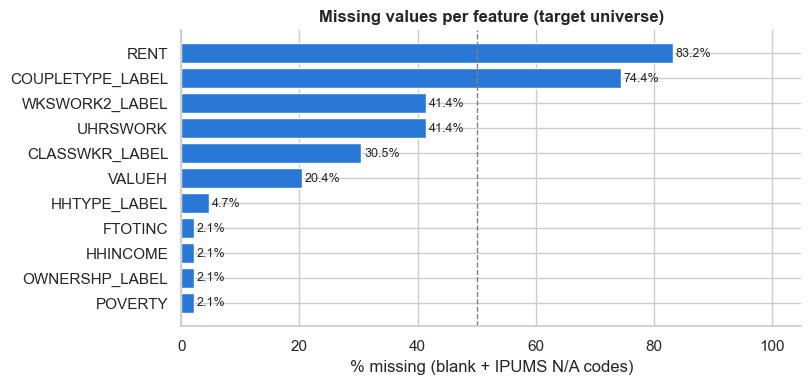

In [8]:
fig, ax = plt.subplots(figsize=(8, max(3, 0.35 * len(missing_table))))
plot_data = missing_table["missing_incl_NA_codes_%"].sort_values()
ax.barh(plot_data.index, plot_data.values, color=BLUE)
for y, v in enumerate(plot_data.values):
    ax.text(v + 0.5, y, f"{v:.1f}%", va="center", fontsize=9)
ax.axvline(50, color="grey", ls="--", lw=1)
ax.set_xlabel("% missing (blank + IPUMS N/A codes)")
ax.set_title("Missing values per feature (target universe)")
ax.set_xlim(0, 105)
save(fig, "02_missing_values")

In [9]:
# Is missingness related to the target? (informative missingness)
miss_vs_target = pd.DataFrame({
    "divorce_rate_if_missing_%": [df.loc[miss[c], TARGET].mean() * 100
                                  for c in missing_table.index],
    "divorce_rate_if_present_%": [df.loc[~miss[c], TARGET].mean() * 100
                                  for c in missing_table.index],
}, index=missing_table.index).round(2)
miss_vs_target

,divorce_rate_if_missing_%,divorce_rate_if_present_%
RENT,0.96,1.79
COUPLETYPE_LABEL,1.34,0.39
UHRSWORK,0.24,1.71
WKSWORK2_LABEL,0.24,1.71
CLASSWKR_LABEL,0.33,1.44
VALUEH,1.96,0.88
HHTYPE_LABEL,6.38,0.84
POVERTY,4.76,1.02
OWNERSHP_LABEL,4.76,1.02
HHINCOME,4.76,1.02


In [11]:
for c, pct in missing_table["missing_incl_NA_codes_%"].items():
    if pct >= 50:
        add_issue("2 Missing", c, f"{pct:.1f}% missing / N/A",
                  "Mostly structural N/A: drop, or encode as 0 + 'is_NA' flag")
    elif pct >= 5:
        add_issue("2 Missing", c, f"{pct:.1f}% missing / N/A",
                  "Impute (median / 'Missing' category) and add a missing-indicator")
    elif pct > 0:
        add_issue("2 Missing", c, f"{pct:.1f}% missing / N/A",
                  "Simple imputation or drop rows")

## 3. Numeric feature distributions
IPUMS N/A codes are replaced by NaN first, otherwise e.g. `9999999` would
dominate the income distributions.

In [12]:
num = df[numeric_cols].copy()
for c, codes in NUMERIC_NA_CODES.items():
    if c in num:
        num[c] = num[c].mask(num[c].isin(codes))

desc = num.describe(percentiles=[.01, .25, .5, .75, .99]).T
desc["skew"] = num.skew()
desc["kurtosis"] = num.kurt()
desc["n_negative"] = (num < 0).sum()
desc["n_zero"] = (num == 0).sum()
desc.round(2)

,count,mean,std,min,1%,25%,50%,75%,99%,max,skew,kurtosis,n_negative,n_zero
AGE,1000.0,55.36,16.39,19.0,22.99,43.0,56.0,68.0,92.0,94.0,0.04,-0.72,0,0
FAMSIZE,1000.0,2.72,1.49,1.0,1.00,2.0,2.0,4.0,7.0,11.0,1.34,2.53,0,0
NCHILD,1000.0,0.73,1.10,0.0,0.00,0.0,0.0,1.0,4.0,7.0,1.59,2.51,0,609
UHRSWORK,586.0,39.88,12.78,1.0,4.00,38.0,40.0,45.0,75.0,99.0,-0.27,2.19,0,0
YRMARR,1000.0,1990.14,18.49,1940.0,1946.00,1976.0,1992.0,2005.0,2023.0,2024.0,-0.36,-0.55,0,0
RENT,168.0,1081.07,801.40,80.0,113.40,515.0,850.0,1400.0,4033.0,5000.0,1.88,4.83,0,0
VALUEH,796.0,389925.13,460032.46,1000.0,5950.00,140000.0,254000.0,486000.0,2117950.0,5744000.0,4.45,33.49,0,0
HHINCOME,979.0,107604.51,120081.61,0.0,2486.40,43050.0,75000.0,128495.0,673420.0,1220000.0,3.63,19.15,0,4
INCTOT,1000.0,50498.19,73340.25,0.0,0.00,12200.0,30000.0,60000.0,418080.0,665000.0,4.12,21.96,0,76
FTOTINC,979.0,105986.22,120236.22,0.0,1534.00,40700.0,73330.0,126500.0,673420.0,1220000.0,3.64,19.23,0,7


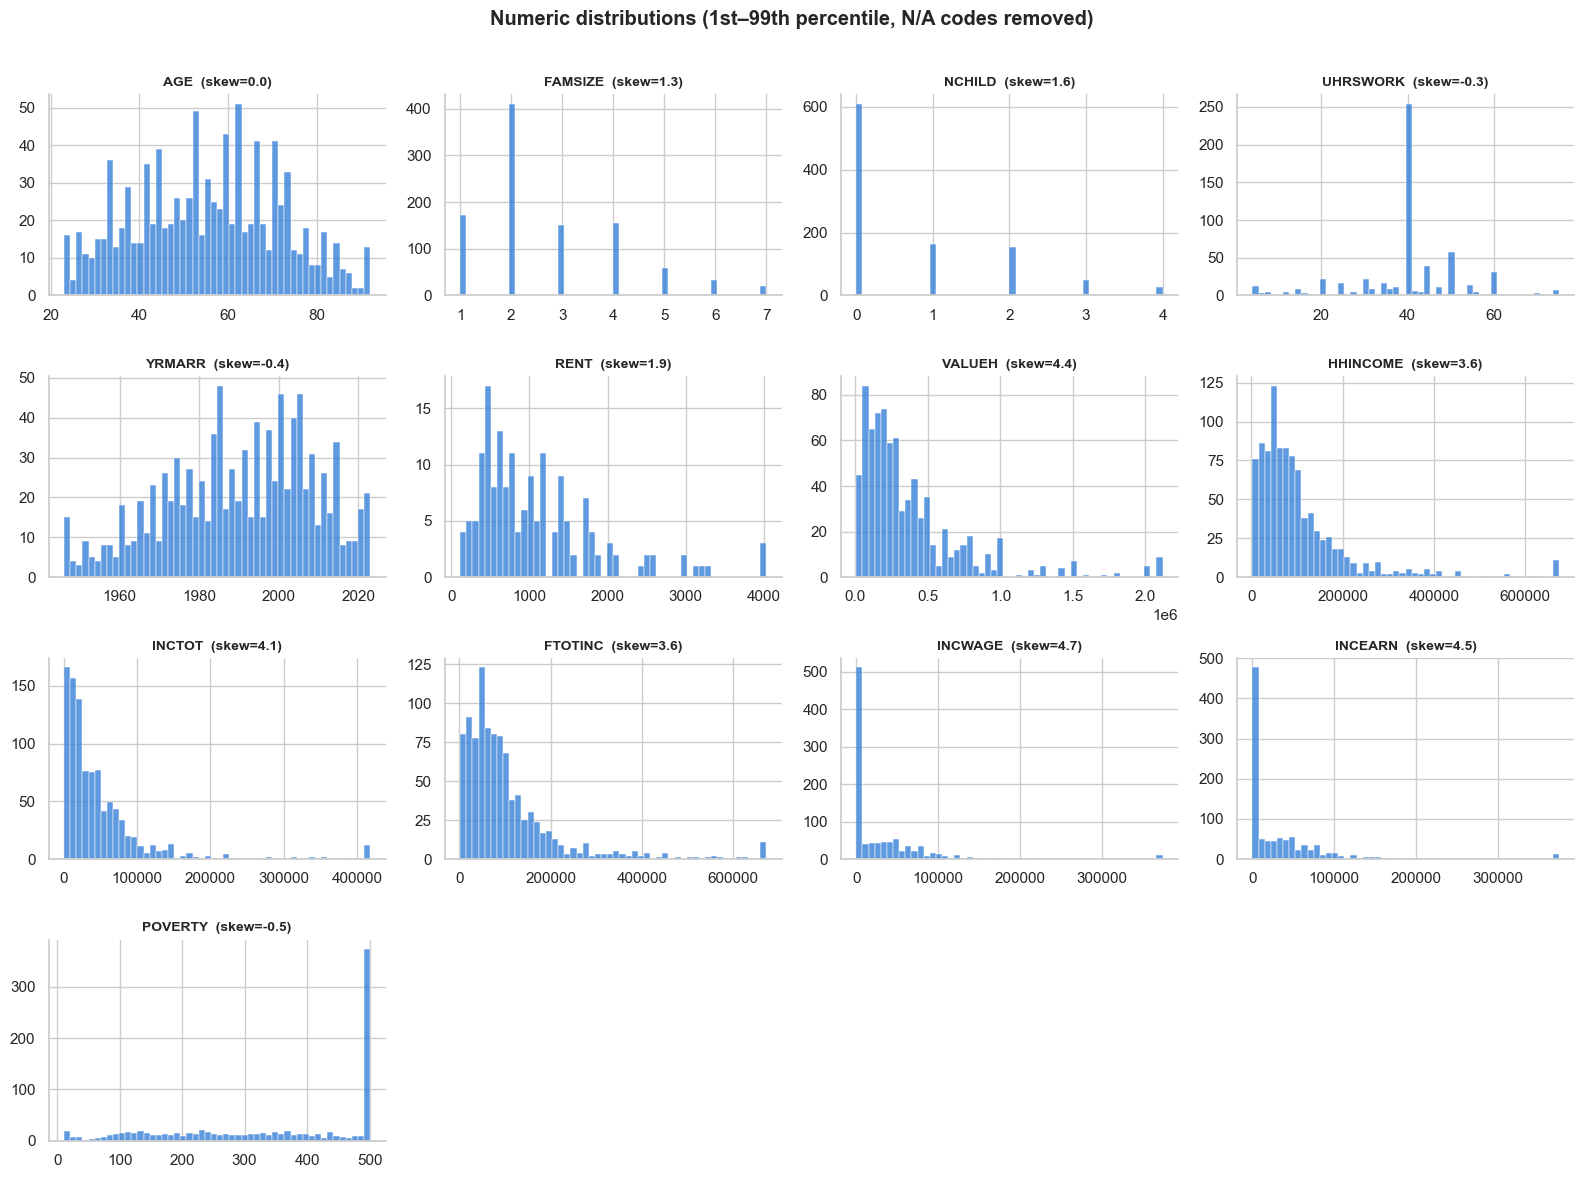

In [13]:
# Histograms – clipped to the 1st–99th percentile so the bulk is visible
ncols = 4
nrows = int(np.ceil(len(numeric_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))
for ax, c in zip(axes.flat, numeric_cols):
    s = num[c].dropna()
    lo, hi = s.quantile([.01, .99])
    sns.histplot(s.clip(lo, hi), bins=50, ax=ax, color=BLUE, edgecolor="white")
    ax.set_title(f"{c}  (skew={s.skew():.1f})", fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
for ax in axes.flat[len(numeric_cols):]:
    ax.remove()
fig.suptitle("Numeric distributions (1st–99th percentile, N/A codes removed)",
             fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.97))
save(fig, "03_numeric_histograms")

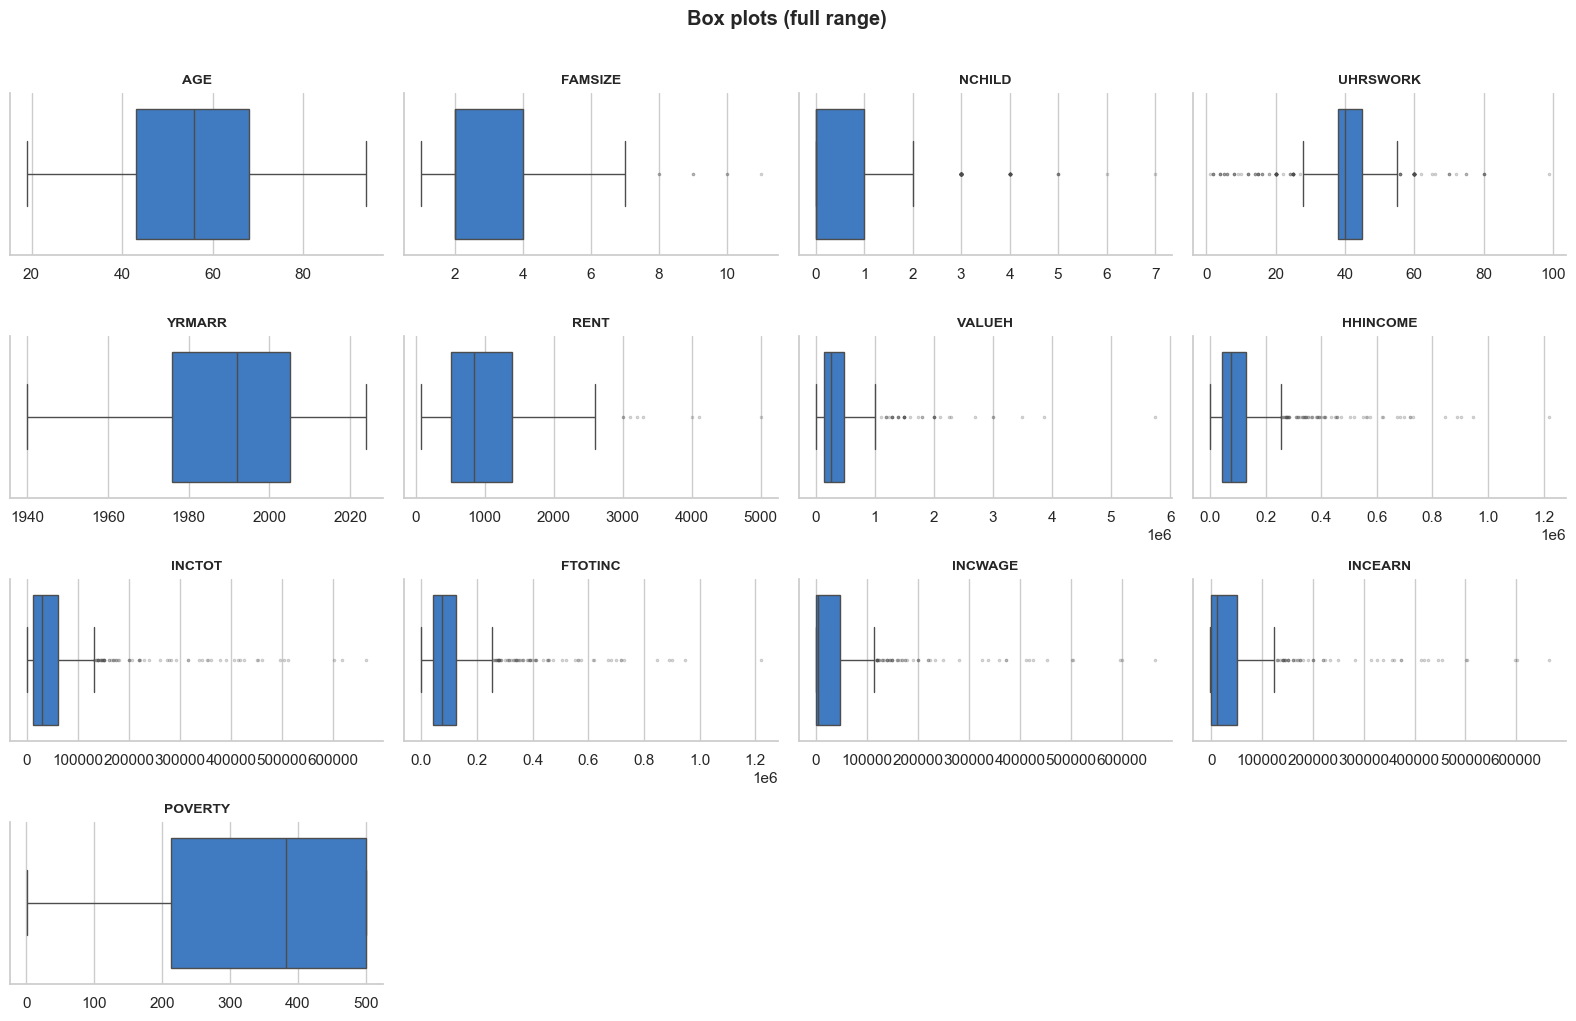

In [14]:
# Box plots on the full range – shows outliers and top-coding
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.6 * nrows))
for ax, c in zip(axes.flat, numeric_cols):
    sns.boxplot(x=num[c].dropna(), ax=ax, color=BLUE, fliersize=1.5,
                flierprops={"alpha": .3})
    ax.set_title(c, fontsize=10)
    ax.set_xlabel("")
for ax in axes.flat[len(numeric_cols):]:
    ax.remove()
fig.suptitle("Box plots (full range)", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.97))
save(fig, "03_numeric_boxplots")

In [15]:
# Outliers (IQR rule) and top-coding (many rows sitting exactly at the max)
rows = []
for c in numeric_cols:
    s = num[c].dropna()
    if s.empty:
        continue
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    n_out = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
    at_max = (s == s.max()).mean()
    rows.append({"feature": c, "IQR_outliers_%": 100 * n_out / len(s),
                 "share_at_max_%": 100 * at_max, "max": s.max(),
                 "skew": s.skew()})
outliers = pd.DataFrame(rows).set_index("feature").round(2)
outliers

,IQR_outliers_%,share_at_max_%,max,skew
feature,,,,
AGE,0.00,0.50,94.0,0.04
FAMSIZE,0.70,0.10,11.0,1.34
NCHILD,7.60,0.10,7.0,1.59
UHRSWORK,21.84,0.17,99.0,-0.27
YRMARR,0.00,0.80,2024.0,-0.36
RENT,4.76,0.60,5000.0,1.88
VALUEH,4.90,0.13,5744000.0,4.45
HHINCOME,7.35,0.10,1220000.0,3.63
INCTOT,6.90,0.10,665000.0,4.12


In [16]:
for c, r in outliers.iterrows():
    if abs(r["skew"]) > 2:
        add_issue("3 Numeric", c, f"Strong skew ({r['skew']:.1f})",
                  "log1p / Yeo-Johnson transform (incomes may be negative)")
    if r["IQR_outliers_%"] > 5:
        add_issue("3 Numeric", c, f"{r['IQR_outliers_%']:.1f}% IQR outliers",
                  "Winsorise (e.g. 1st/99th pct) or use robust scaling")
    if r["share_at_max_%"] > 0.5 and r["max"] > 0:
        add_issue("3 Numeric", c,
                  f"{r['share_at_max_%']:.1f}% of rows at max ({r['max']:,.0f}) – top-coded",
                  "Treat max as censored; consider binning")
for c in numeric_cols:
    if desc.loc[c, "n_negative"] > 0:
        add_issue("3 Numeric", c, f"{int(desc.loc[c, 'n_negative']):,} negative values",
                  "Valid (business losses) – avoid plain log; use signed log / Yeo-Johnson")

# Incomes are in nominal dollars across 2008/2016/2024
add_issue("3 Numeric", "HHINCOME, INCTOT, FTOTINC, INCWAGE, INCEARN, RENT, VALUEH",
          "Nominal dollars across 2008/2016/2024 – not comparable over time",
          "Inflation-adjust to one year (CPI) or use within-year percentiles")

## 4. Categorical feature distributions
Cardinality and category frequencies decide the encoding (one-hot vs
ordinal vs target/frequency encoding) and which rare levels to merge.

In [17]:
cat_summary = pd.DataFrame({
    "n_categories": [df[c].nunique() for c in feature_label_cols],
    "top_category": [df[c].value_counts().index[0] for c in feature_label_cols],
    "top_share_%": [df[c].value_counts(normalize=True).iloc[0] * 100
                    for c in feature_label_cols],
    "n_rare_<1%": [(df[c].value_counts(normalize=True) < 0.01).sum()
                   for c in feature_label_cols],
}, index=feature_label_cols).round(2).sort_values("n_categories")
cat_summary

,n_categories,top_category,top_share_%,n_rare_<1%
SEX_LABEL,2,Female,54.90,0
LABFORCE_LABEL,2,"Yes, in the labor force",55.40,0
OWNERSHP_LABEL,3,Owned or being bought (loan),79.60,0
MARRNO_LABEL,3,Married once,74.80,0
EMPSTAT_LABEL,3,Employed,53.60,0
CLASSWKR_LABEL,3,Works for wages,61.00,0
COUPLETYPE_LABEL,4,Opposite-sex husband/wife/spouse household,71.68,1
MIGRATE1_LABEL,4,Same house,91.20,1
METRO_LABEL,5,In metropolitan area: Not in central/principal...,30.70,0
MARST_LABEL,5,"Married, spouse present",71.90,0


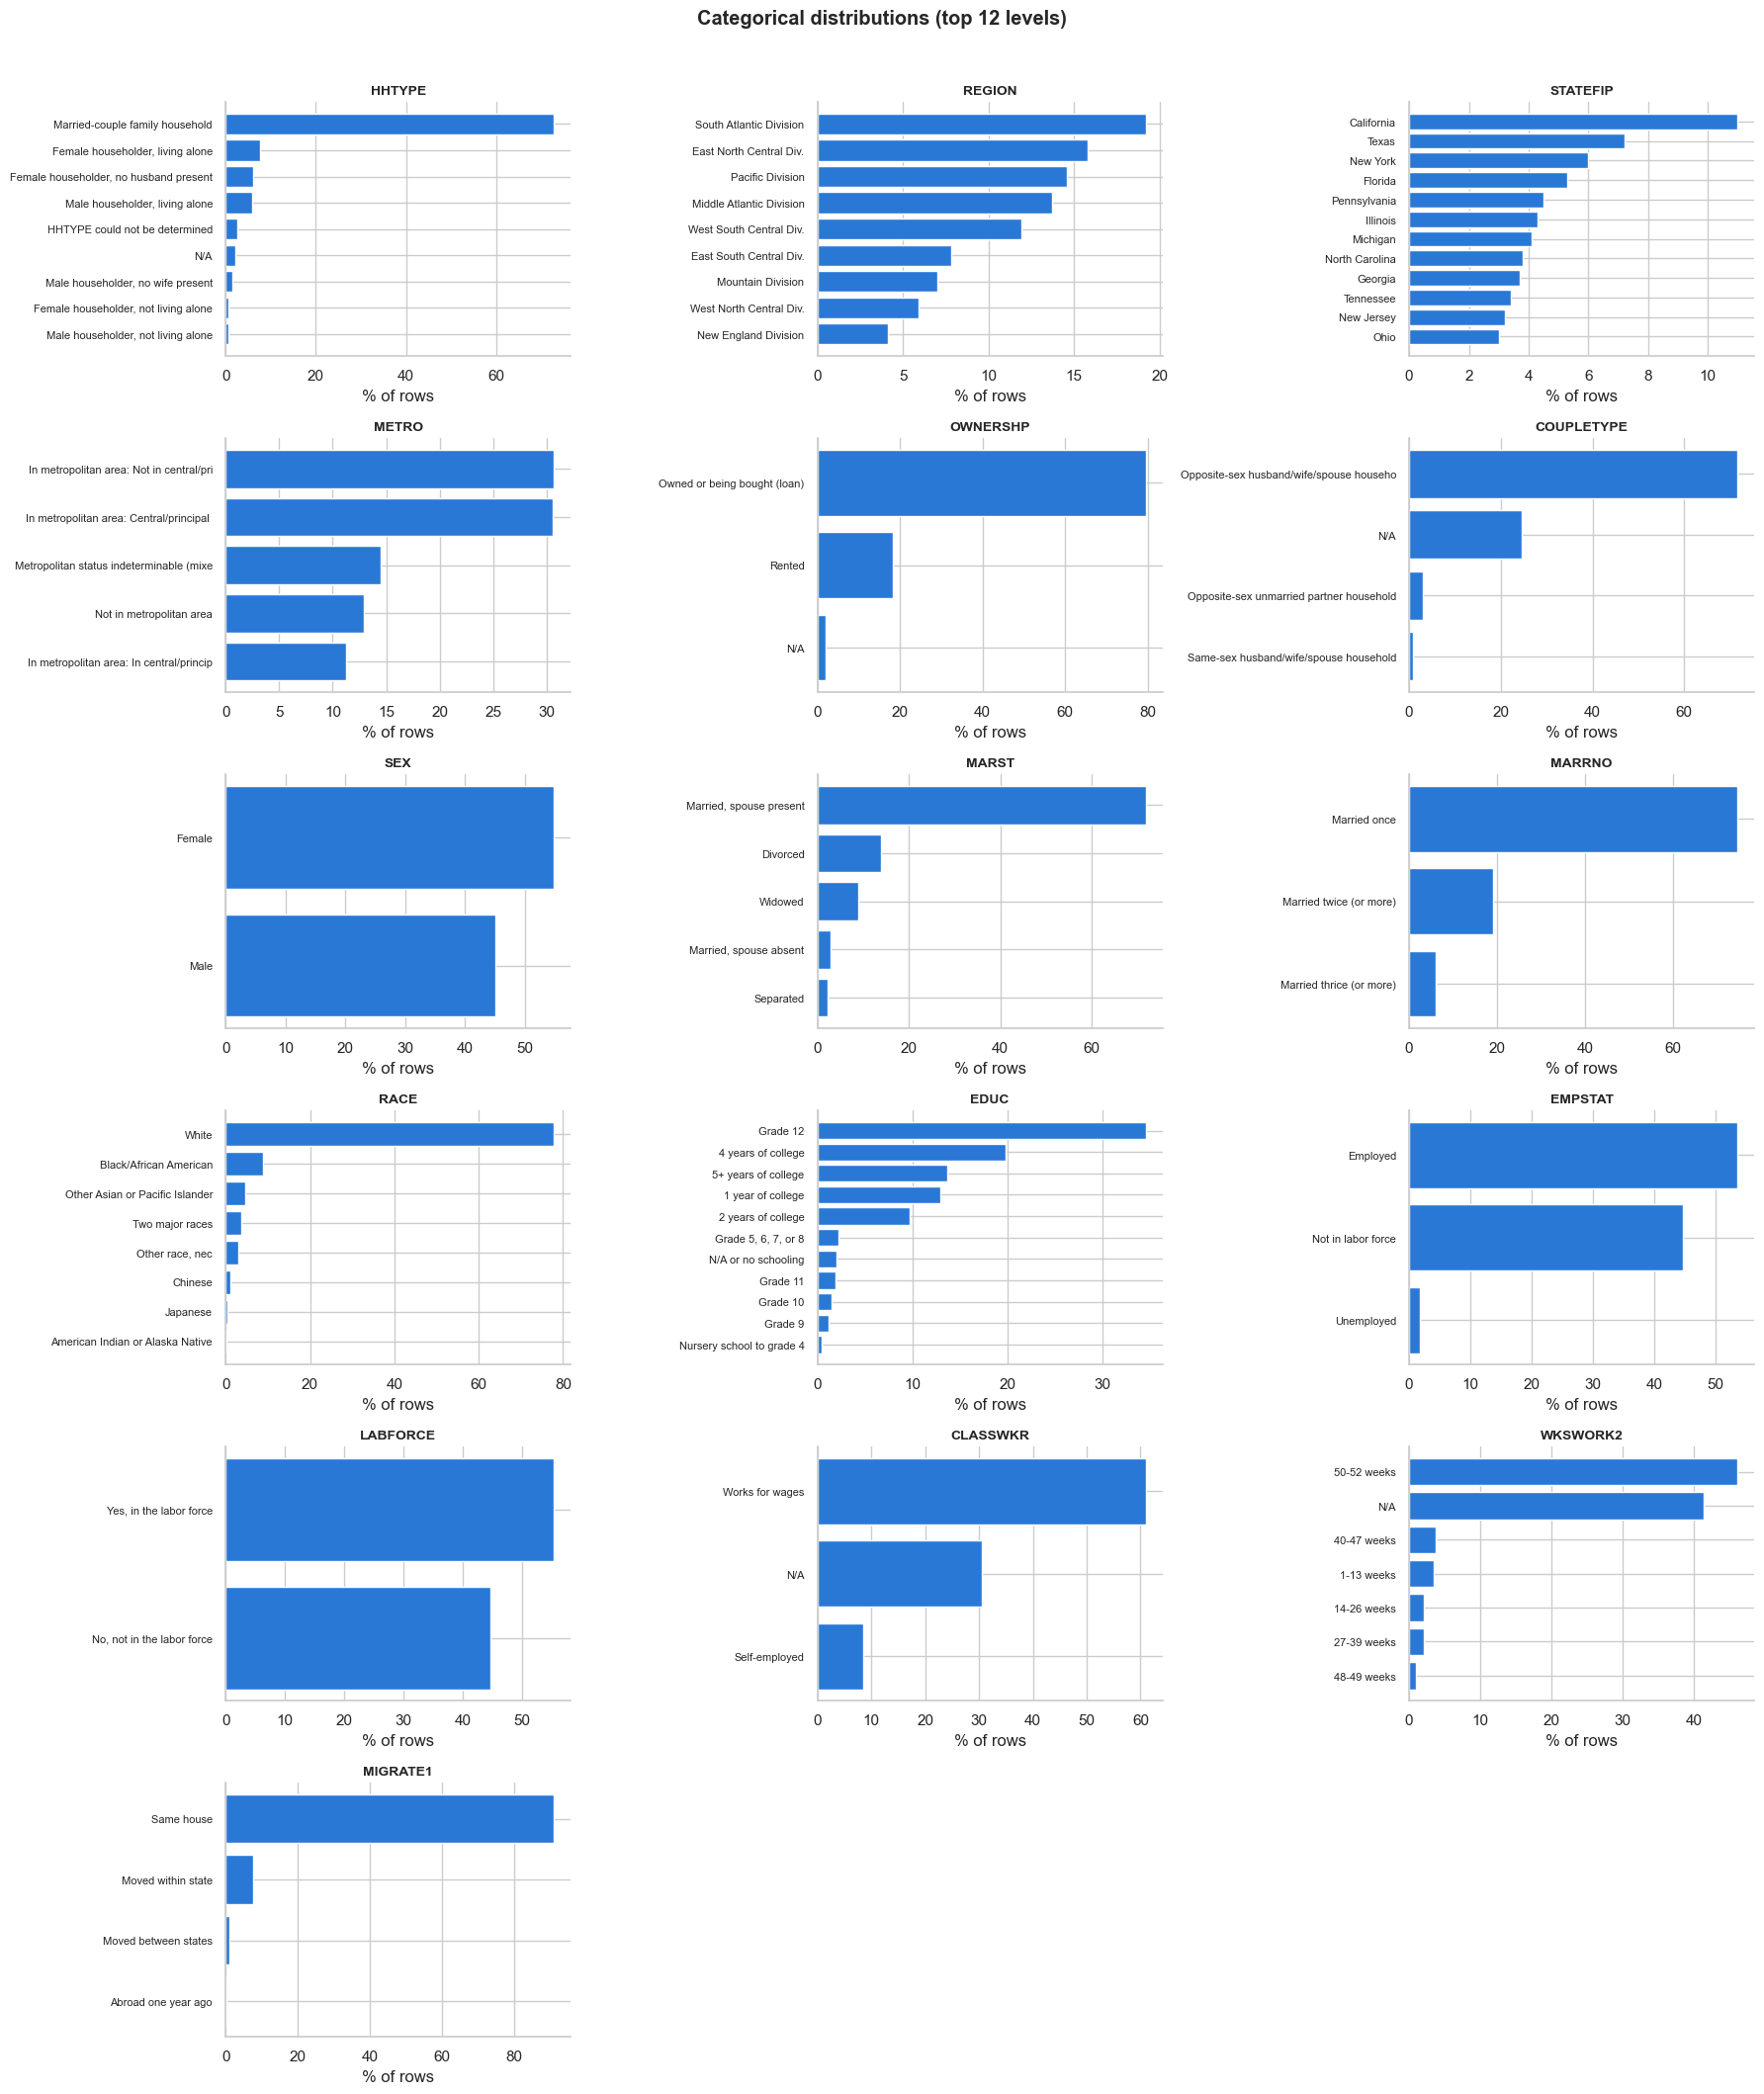

In [18]:
ncols = 3
nrows = int(np.ceil(len(feature_label_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 3.6 * nrows))
for ax, c in zip(axes.flat, feature_label_cols):
    vc = df[c].value_counts(normalize=True).head(12)[::-1] * 100
    ax.barh([str(i)[:40] for i in vc.index], vc.values, color=BLUE)
    ax.set_title(c.replace("_LABEL", ""), fontsize=10)
    ax.set_xlabel("% of rows")
    ax.tick_params(axis="y", labelsize=8)
for ax in axes.flat[len(feature_label_cols):]:
    ax.remove()
fig.suptitle("Categorical distributions (top 12 levels)", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.97))
save(fig, "04_categorical_bars")

In [19]:
for c, r in cat_summary.iterrows():
    if r["n_categories"] > 15:
        add_issue("4 Categorical", c, f"High cardinality ({r['n_categories']} levels)",
                  "Target / frequency encoding, or group (e.g. state → region)")
    if r["n_rare_<1%"] > 0:
        add_issue("4 Categorical", c, f"{r['n_rare_<1%']} rare levels (<1%)",
                  "Merge rare levels into 'Other'")
    if r["top_share_%"] > 90:
        add_issue("4 Categorical", c, f"Near-constant ({r['top_share_%']:.1f}% one level)",
                  "Likely low value – consider dropping")

# Naturally ordered variables should be ordinal-encoded, not one-hot
add_issue("4 Categorical", "EDUC_LABEL, WKSWORK2_LABEL",
          "Ordered categories", "Ordinal encoding (preserve order)")

## 5. Correlations
* **Numeric:** Spearman (rank-based – robust to skew and outliers).
* **Categorical:** Cramér's V (association between two categoricals, 0–1).

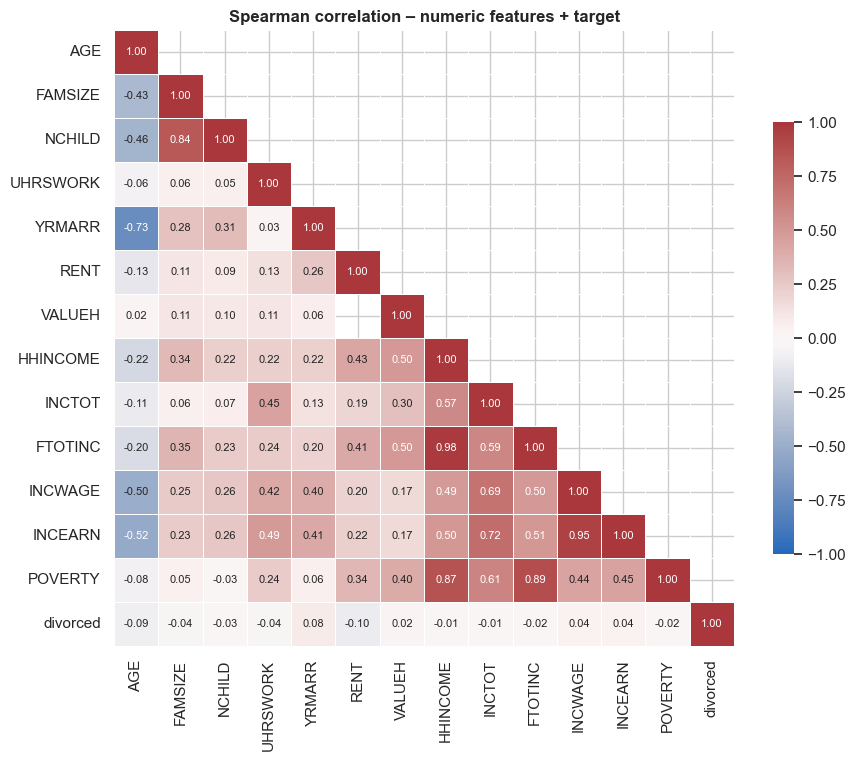

In [20]:
corr = num.assign(**{TARGET: df[TARGET]}).corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap="vlag", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 8},
            linewidths=.5, cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Spearman correlation – numeric features + target")
save(fig, "05_numeric_correlation")

In [21]:
high_corr = (corr.where(np.triu(np.ones_like(corr, dtype=bool), k=1))
                 .stack().rename("rho").reset_index())
high_corr = high_corr[high_corr["rho"].abs() >= 0.8].sort_values(
    "rho", key=abs, ascending=False)
for _, r in high_corr.iterrows():
    add_issue("5 Correlation", f"{r['level_0']} ~ {r['level_1']}",
              f"Highly correlated (ρ={r['rho']:.2f})",
              "Keep one, combine, or reduce with PCA")
high_corr

,level_0,level_1,rho
70,HHINCOME,FTOTINC,0.982613
84,INCWAGE,INCEARN,0.946232
82,FTOTINC,POVERTY,0.886671
73,HHINCOME,POVERTY,0.866837
13,FAMSIZE,NCHILD,0.835333


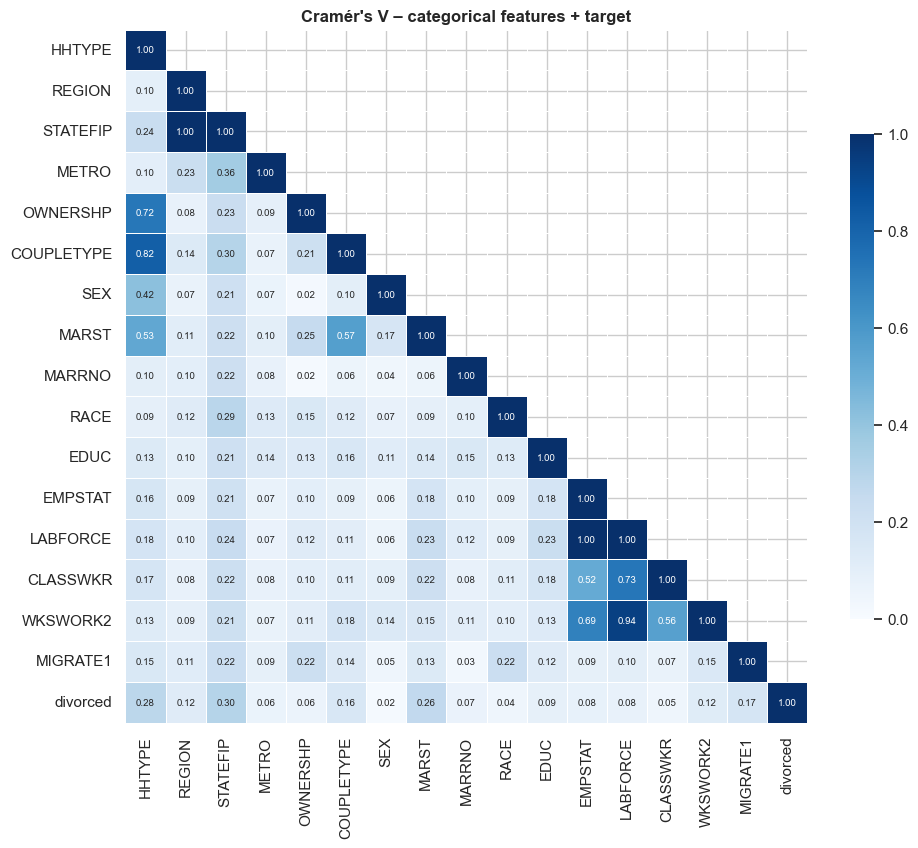

In [22]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    if min(table.shape) < 2:
        return np.nan
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.values.sum()
    r, k = table.shape
    return np.sqrt(chi2 / (n * (min(r, k) - 1)))


cv_cols = feature_label_cols + [TARGET]
cv = pd.DataFrame(np.eye(len(cv_cols)), index=cv_cols, columns=cv_cols)
for i, a in enumerate(cv_cols):
    for b in cv_cols[i + 1:]:
        cv.loc[a, b] = cv.loc[b, a] = cramers_v(df[a], df[b])
cv.index = cv.columns = [c.replace("_LABEL", "") for c in cv_cols]

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(cv, mask=np.triu(np.ones_like(cv, dtype=bool), k=1),
            cmap="Blues", vmin=0, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=.5, cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Cramér's V – categorical features + target")
save(fig, "05_categorical_cramers_v")

In [23]:
cv_pairs = (cv.where(np.triu(np.ones_like(cv, dtype=bool), k=1))
              .stack().rename("cramers_v").reset_index())
cv_pairs = cv_pairs[cv_pairs["cramers_v"] >= 0.6].sort_values(
    "cramers_v", ascending=False)
for _, r in cv_pairs.iterrows():
    add_issue("5 Correlation", f"{r['level_0']} ~ {r['level_1']}",
              f"Strong association (Cramér's V={r['cramers_v']:.2f})",
              "Redundant – keep the more informative one")
cv_pairs

,level_0,level_1,cramers_v
16,REGION,STATEFIP,1.000000
121,EMPSTAT,LABFORCE,1.000000
127,LABFORCE,WKSWORK2,0.937647
4,HHTYPE,COUPLETYPE,0.816497
126,LABFORCE,CLASSWKR,0.730330
3,HHTYPE,OWNERSHP,0.722928
123,EMPSTAT,WKSWORK2,0.689015


## 6. Target relationships
Divorce rate by feature, **weighted by `PERWT`** so rates represent the US
population rather than the sample design.

In [24]:
# Divorce rate by survey year – the core research question
by_year = df.groupby("YEAR").apply(
    lambda g: pd.Series({"rows": len(g),
                         "divorces": g[TARGET].sum(),
                         "rate_unweighted_%": 100 * g[TARGET].mean(),
                         "rate_weighted_%": 100 * weighted_rate(g[TARGET], g[WEIGHT])}))
by_year.round(3)

/var/folders/1q/xz5yj7qj26z8xksf2875nk180000gn/T/ipykernel_83946/2109658943.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_year = df.groupby("YEAR").apply(


,rows,divorces,rate_unweighted_%,rate_weighted_%
YEAR,,,,
2008,319.0,1.0,0.313,0.304
2016,342.0,5.0,1.462,2.151
2024,339.0,5.0,1.475,2.192


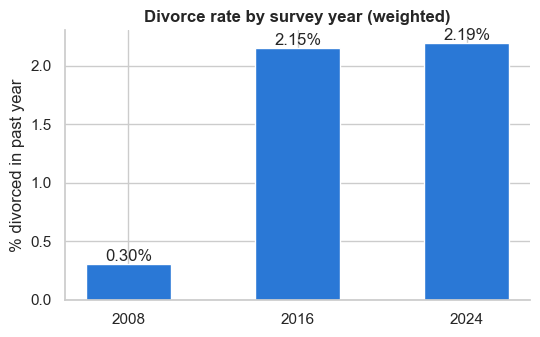

In [25]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(by_year.index.astype(str), by_year["rate_weighted_%"], color=BLUE, width=.5)
for x, v in enumerate(by_year["rate_weighted_%"]):
    ax.text(x, v, f"{v:.2f}%", ha="center", va="bottom")
ax.set_ylabel("% divorced in past year")
ax.set_title("Divorce rate by survey year (weighted)")
save(fig, "06_rate_by_year")

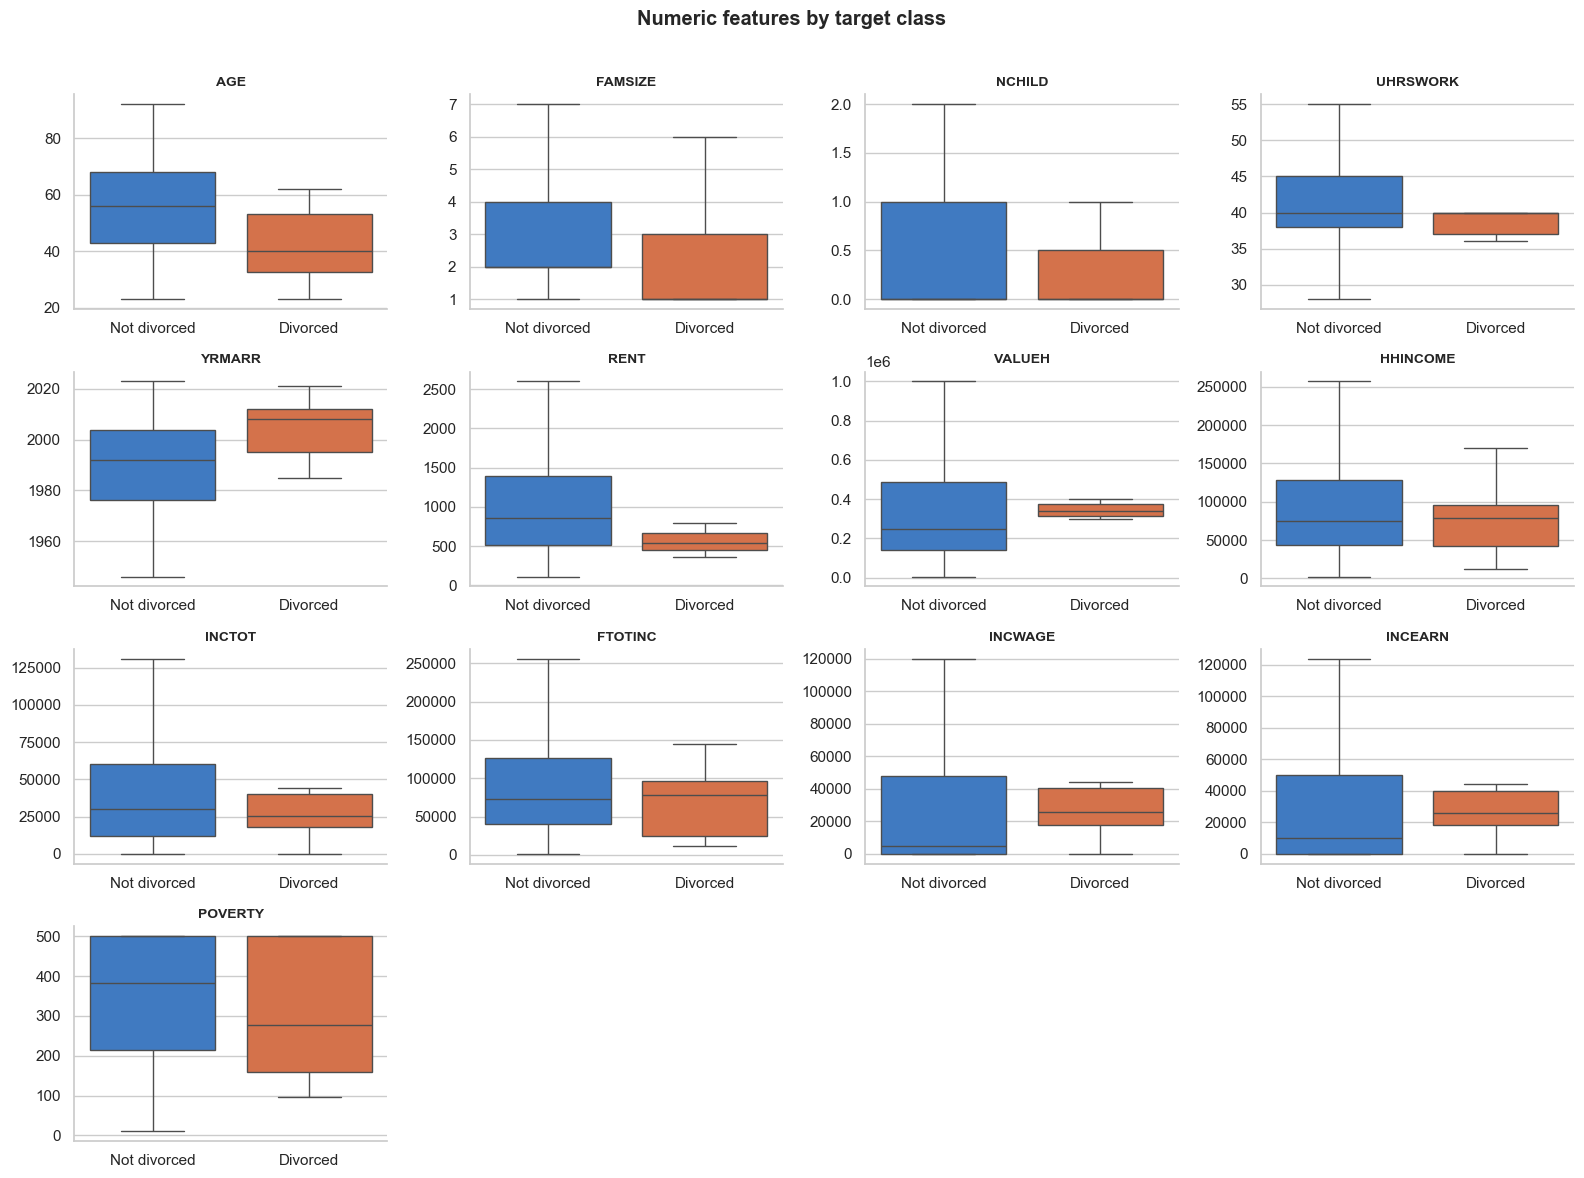

In [26]:
# Numeric features vs target: distributions by class (1st–99th pct)
ncols = 4
nrows = int(np.ceil(len(numeric_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))
tmp = num.assign(**{TARGET: df[TARGET]})
for ax, c in zip(axes.flat, numeric_cols):
    lo, hi = tmp[c].quantile([.01, .99])
    sns.boxplot(data=tmp.assign(**{c: tmp[c].clip(lo, hi)}), x=TARGET, y=c,
                hue=TARGET, palette=CLASS_PALETTE, legend=False,
                showfliers=False, ax=ax)
    ax.set_title(c, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_xticks([0, 1], ["Not divorced", "Divorced"])
for ax in axes.flat[len(numeric_cols):]:
    ax.remove()
fig.suptitle("Numeric features by target class", fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.97))
save(fig, "06_numeric_vs_target")

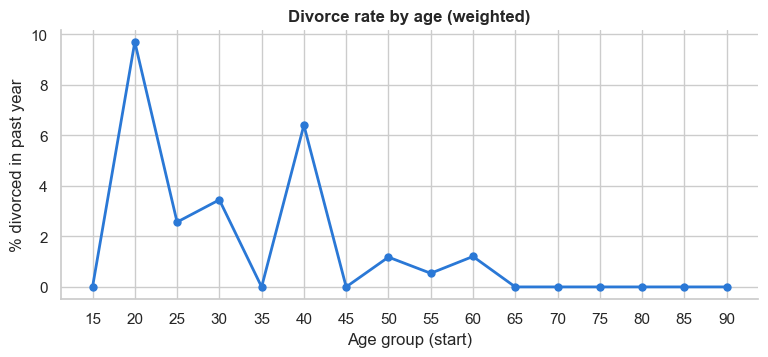

In [27]:
# Divorce rate across age – non-linear relationships show up here
age_bins = pd.cut(num["AGE"], bins=range(15, 100, 5), right=False)
age_rate = df.groupby(age_bins, observed=True).apply(
    lambda g: 100 * weighted_rate(g[TARGET], g[WEIGHT]))
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot([str(i.left) for i in age_rate.index], age_rate.values,
        color=BLUE, lw=2, marker="o", ms=5)
ax.set_xlabel("Age group (start)")
ax.set_ylabel("% divorced in past year")
ax.set_title("Divorce rate by age (weighted)")
save(fig, "06_rate_by_age")

/var/folders/1q/xz5yj7qj26z8xksf2875nk180000gn/T/ipykernel_83946/3307866171.py:8: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  rates = g.apply(lambda x: 100 * weighted_rate(x[TARGET], x[WEIGHT]))
/var/folders/1q/xz5yj7qj26z8xksf2875nk180000gn/T/ipykernel_83946/3307866171.py:8: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  rates = g.apply(lambda x: 100 * weighted_rate(x[TARGET], x[WEIGHT]))
/var/folders/1q/xz5yj7qj26

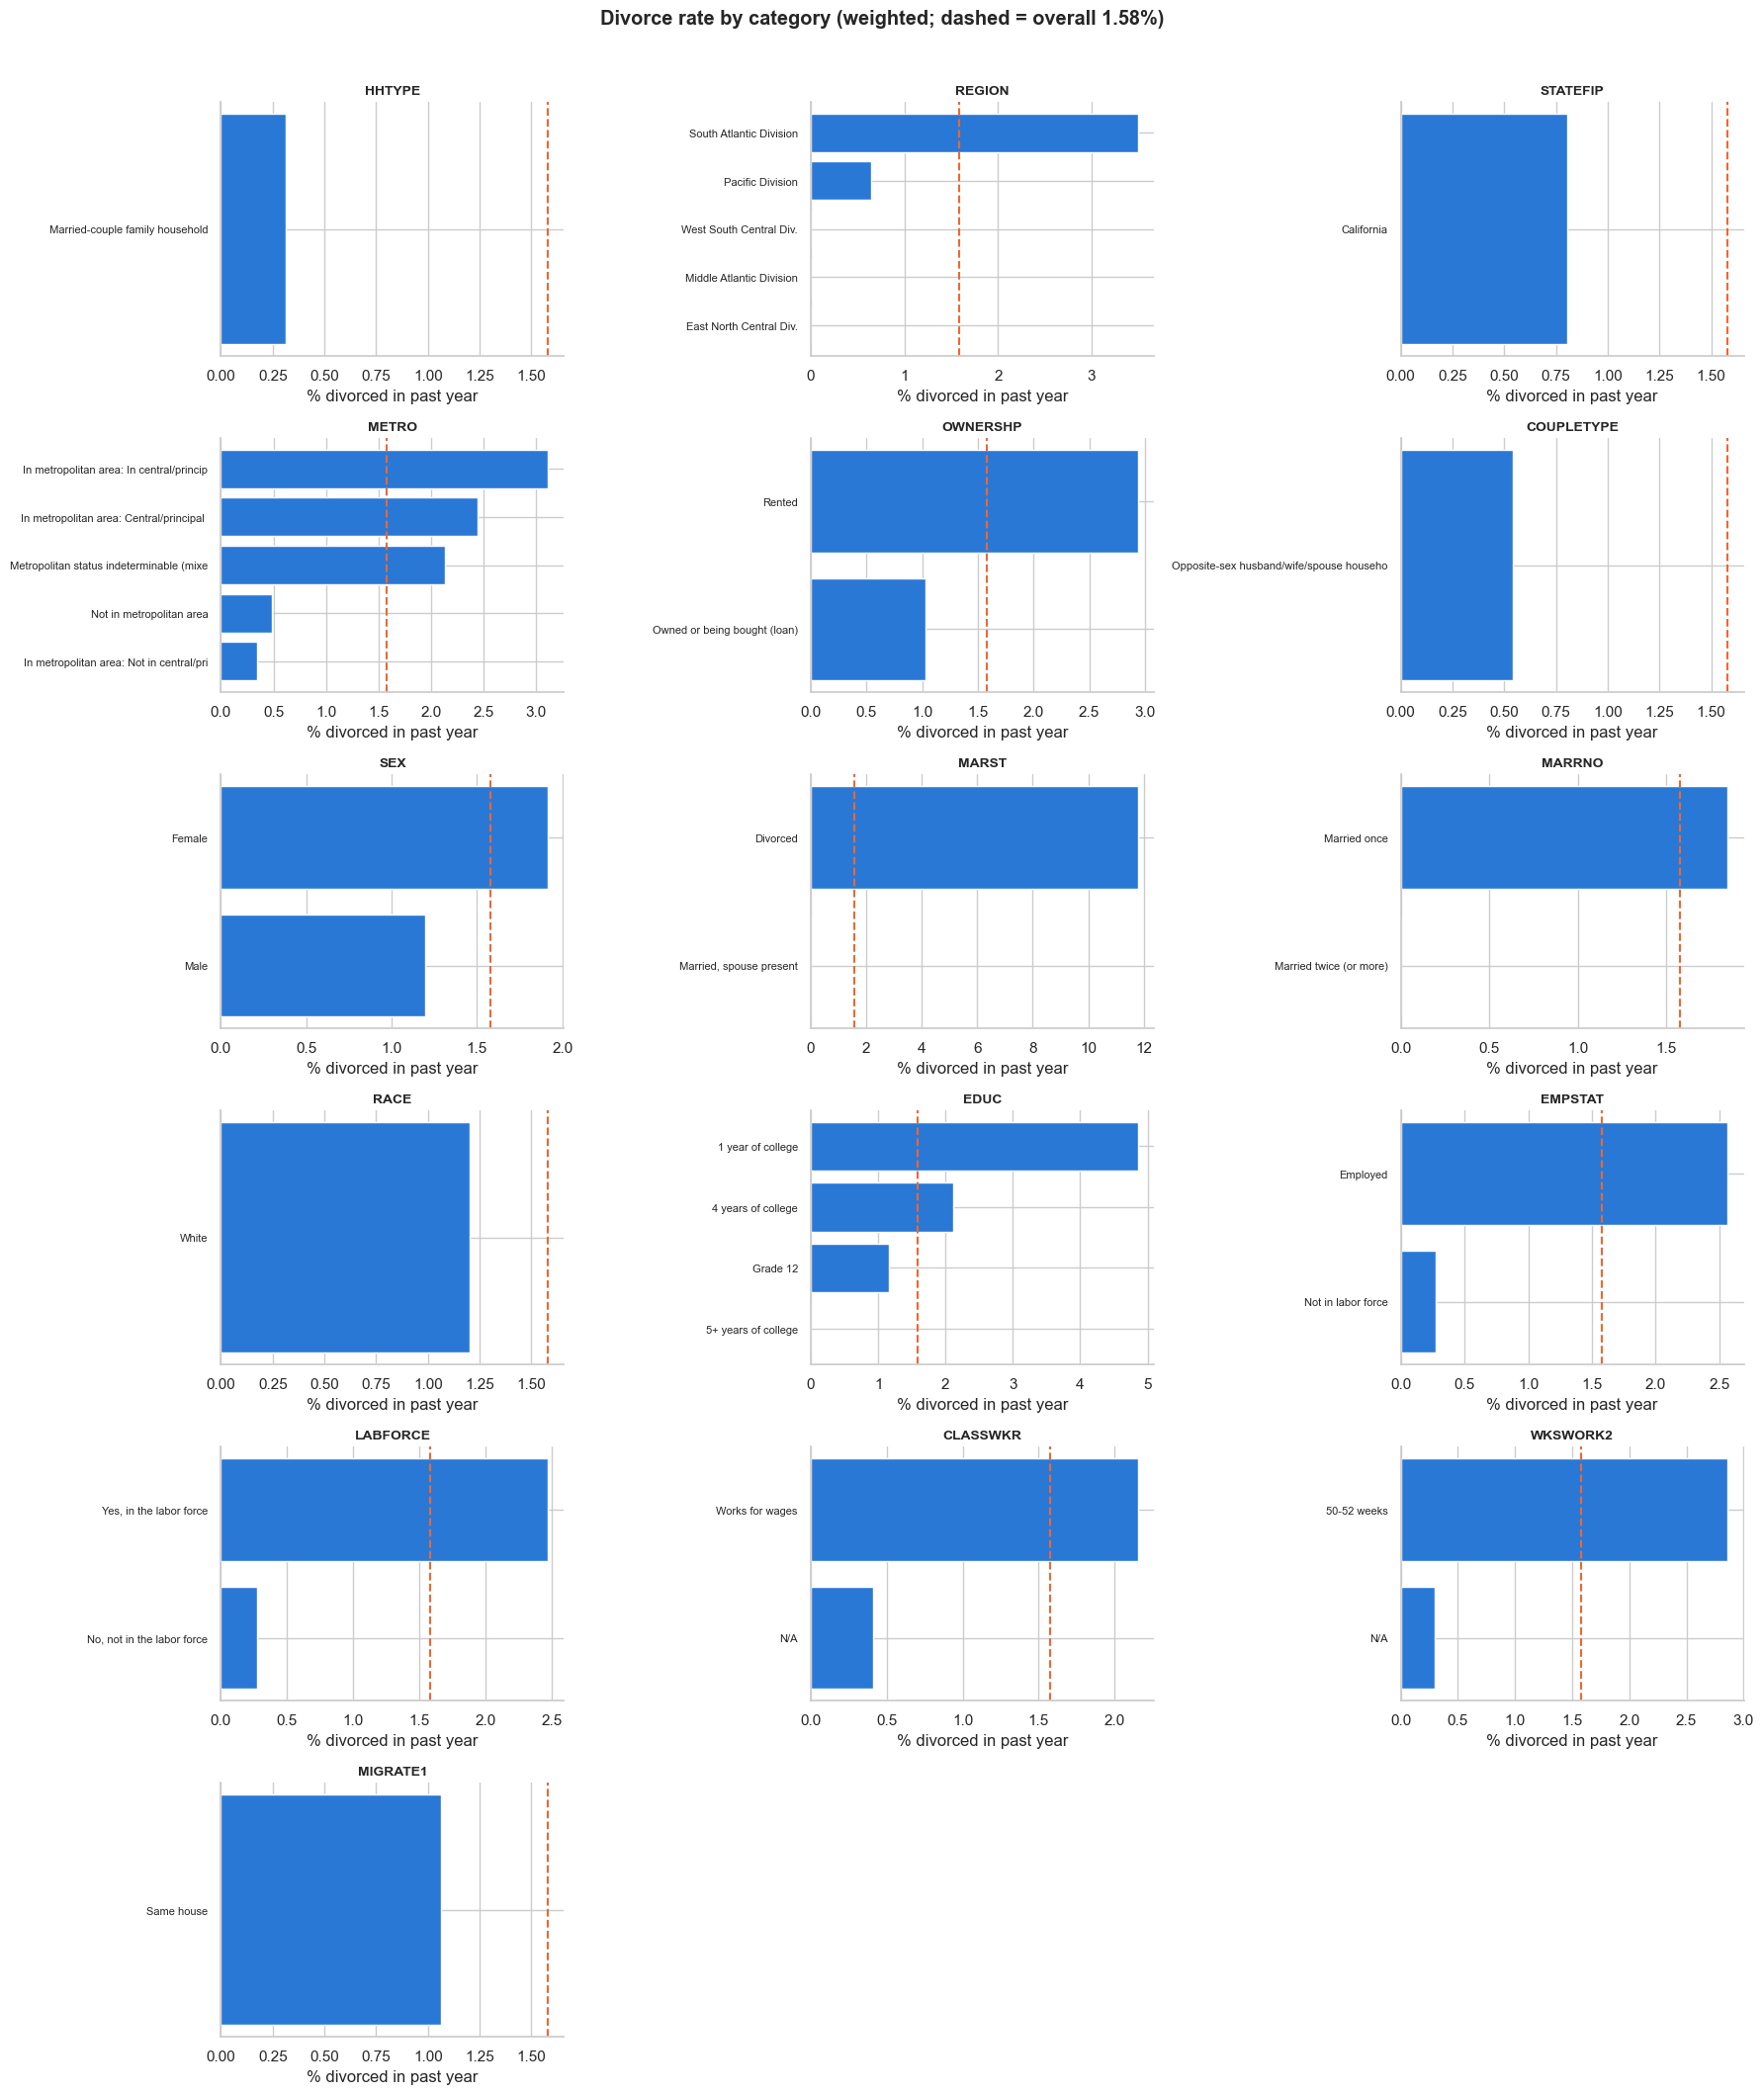

In [28]:
# Categorical features vs target: weighted divorce rate per level
overall = 100 * weighted_rate(df[TARGET], df[WEIGHT])
ncols = 3
nrows = int(np.ceil(len(feature_label_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 3.6 * nrows))
for ax, c in zip(axes.flat, feature_label_cols):
    g = df.groupby(c, observed=True)
    rates = g.apply(lambda x: 100 * weighted_rate(x[TARGET], x[WEIGHT]))
    rates = rates[g.size() >= 100]             # hide unstable tiny levels
    rates = rates.sort_values().tail(12)
    ax.barh([str(i)[:40] for i in rates.index], rates.values, color=BLUE)
    ax.axvline(overall, color=ORANGE, ls="--", lw=1.5)
    ax.set_title(c.replace("_LABEL", ""), fontsize=10)
    ax.set_xlabel("% divorced in past year")
    ax.tick_params(axis="y", labelsize=8)
for ax in axes.flat[len(feature_label_cols):]:
    ax.remove()
fig.suptitle(f"Divorce rate by category (weighted; dashed = overall {overall:.2f}%)",
             fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.97))
save(fig, "06_categorical_vs_target")

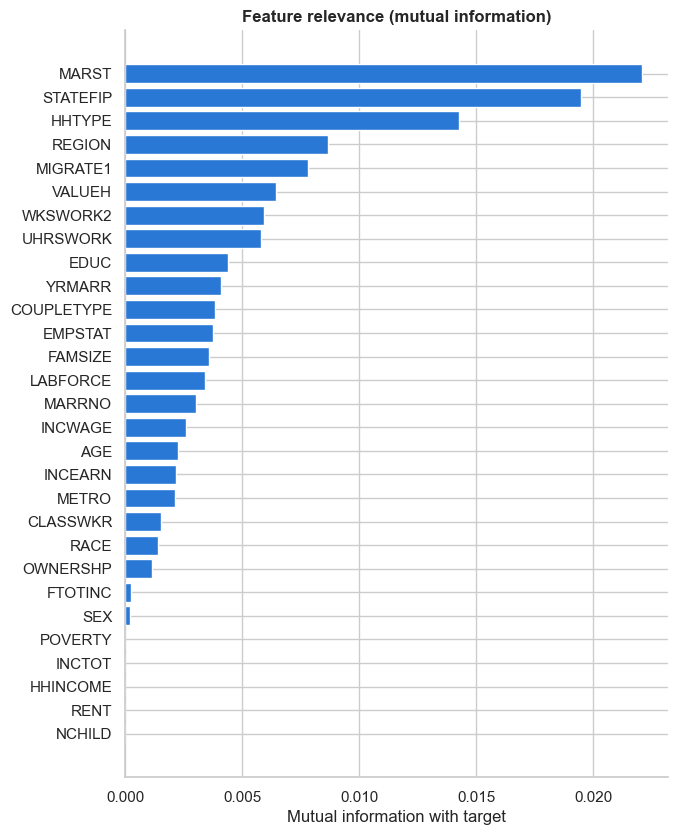

In [29]:
# Mutual information ranking (model-free, captures non-linear signal).
# Computed on a sample for speed.
mi_df = df.sample(n=min(len(df), 300_000), random_state=RANDOM_STATE)
X_mi = pd.concat([
    num.loc[mi_df.index].fillna(-1),
    mi_df[feature_label_cols].apply(lambda s: s.cat.codes),
], axis=1)
discrete = [False] * len(numeric_cols) + [True] * len(feature_label_cols)
mi = pd.Series(mutual_info_classif(X_mi, mi_df[TARGET], discrete_features=discrete,
                                   random_state=RANDOM_STATE),
               index=X_mi.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 0.3 * len(mi) + 1))
ax.barh(mi.index.str.replace("_LABEL", ""), mi.values, color=BLUE)
ax.set_xlabel("Mutual information with target")
ax.set_title("Feature relevance (mutual information)")
save(fig, "06_mutual_information")

In [30]:
# Leakage check: features that (partly) encode the outcome itself.
# Someone divorced in the past year is, by definition, currently divorced or
# recently remarried, so MARST / MARRNO / YRMARR describe the *result*.
leak_candidates = ["MARST_LABEL", "MARRNO_LABEL", "YRMARR"]
print(pd.crosstab(df["MARST_LABEL"], df[TARGET], normalize="columns").round(3))
add_issue("6 Target", ", ".join(leak_candidates),
          "Potential target leakage (marital status after the divorce event)",
          "Exclude from predictors, or justify explicitly in the report")

divorced                     0    1
MARST_LABEL                        
Divorced                 0.129  1.0
Married, spouse absent   0.029  0.0
Married, spouse present  0.727  0.0
Separated                0.023  0.0
Widowed                  0.091  0.0


## 7. Class balance

In [31]:
balance = pd.DataFrame({
    "rows": df[TARGET].value_counts(),
    "share_unweighted_%": df[TARGET].value_counts(normalize=True) * 100,
    "share_weighted_%": df.groupby(TARGET)[WEIGHT].sum() / df[WEIGHT].sum() * 100,
}).rename(index={0: "Not divorced", 1: "Divorced"}).round(3)
balance

,rows,share_unweighted_%,share_weighted_%
divorced,,,
Not divorced,989,98.9,98.421
Divorced,11,1.1,1.579


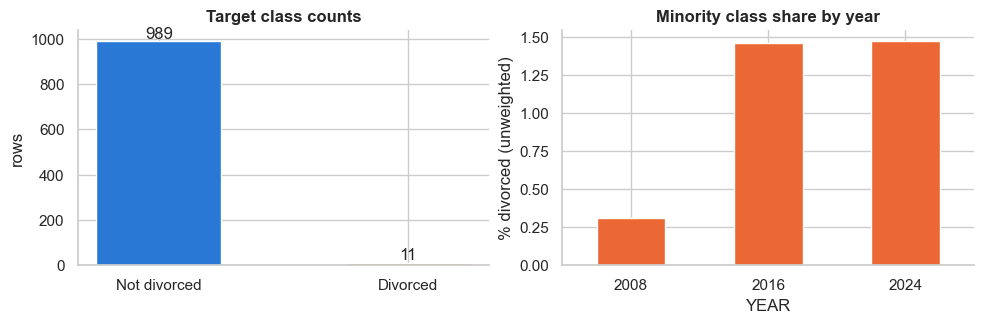

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].bar(balance.index, balance["rows"], color=[BLUE, ORANGE], width=.5)
for x, v in enumerate(balance["rows"]):
    axes[0].text(x, v, f"{v:,}", ha="center", va="bottom")
axes[0].set_title("Target class counts")
axes[0].set_ylabel("rows")

yr = df.groupby(["YEAR", TARGET]).size().unstack(fill_value=0)
(yr.div(yr.sum(axis=1), axis=0)[1] * 100).plot.bar(ax=axes[1], color=ORANGE, rot=0)
axes[1].set_title("Minority class share by year")
axes[1].set_ylabel("% divorced (unweighted)")
fig.tight_layout(rect=(0, 0, 1, 0.97))
save(fig, "07_class_balance")

In [33]:
minority = balance["share_unweighted_%"].min()
imbalance_ratio = balance["rows"].max() / balance["rows"].min()
print(f"Minority class: {minority:.2f}%  |  imbalance ratio ≈ {imbalance_ratio:,.0f}:1")
if minority < 10:
    add_issue("7 Class balance", TARGET,
              f"Severe imbalance – minority {minority:.2f}% (≈{imbalance_ratio:,.0f}:1)",
              "Stratified splits; class_weight / resampling (SMOTE, undersampling); "
              "evaluate with PR-AUC, recall, F1 – not accuracy")

Minority class: 1.10%  |  imbalance ratio ≈ 90:1


## 8. Identified problems → actions for 3.2

In [34]:
issues_df = pd.DataFrame(issues)
issues_df.to_csv(FIG_DIR / "eda_issues.csv", index=False)
with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(issues_df)
print(f"\n{len(issues_df)} issues saved to {FIG_DIR / 'eda_issues.csv'}; "
      f"figures in {FIG_DIR}/")

,section,feature,problem,action_3_2
0,1 Overview,DIVINYR_LABEL,0.0% of rows have no target (N/A or Suppressed),"Restrict modelling data to DIVINYR in {Yes, Blank (No)}"
1,2 Missing,RENT,83.2% missing / N/A,"Mostly structural N/A: drop, or encode as 0 + 'is_NA' flag"
2,2 Missing,COUPLETYPE_LABEL,74.4% missing / N/A,"Mostly structural N/A: drop, or encode as 0 + 'is_NA' flag"
3,2 Missing,UHRSWORK,41.4% missing / N/A,Impute (median / 'Missing' category) and add a missing-indicator
4,2 Missing,WKSWORK2_LABEL,41.4% missing / N/A,Impute (median / 'Missing' category) and add a missing-indicator
5,2 Missing,CLASSWKR_LABEL,30.5% missing / N/A,Impute (median / 'Missing' category) and add a missing-indicator
6,2 Missing,VALUEH,20.4% missing / N/A,Impute (median / 'Missing' category) and add a missing-indicator
7,2 Missing,HHTYPE_LABEL,4.7% missing / N/A,Simple imputation or drop rows
8,2 Missing,POVERTY,2.1% missing / N/A,Simple imputation or drop rows
9,2 Missing,OWNERSHP_LABEL,2.1% missing / N/A,Simple imputation or drop rows



64 issues saved to figures/eda/eda_issues.csv; figures in figures/eda/
